# Spatial Validation

Companion to [`notes/spatial_statistics/spatial_validation.md`](../../notes/spatial_statistics/spatial_validation.md).

We build a spatially smooth random field, predict it with inverse-distance weighting (a deliberately simple predictor), and compare random, blocked, and buffered cross-validation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

rng = np.random.default_rng(7)
n = 500
coords = rng.uniform(0, 10, size=(n, 2))      # km

# Smooth random field via random Fourier features plus small noise
K = 40
freq = rng.normal(scale=1/1.5, size=(K, 2))
phase = rng.uniform(0, 2*np.pi, K)
field = np.sqrt(2/K) * np.cos(coords @ freq.T + phase).sum(1)
y = field + rng.normal(scale=0.15, size=n)
print("n =", n, " var(y) =", y.var().round(3))

n = 500  var(y) = 1.548


## Predictor and RMSE

IDW with $k$ nearest training points and $w_i=1/(d_i^p+\epsilon)$. RMSE is $\sqrt{\frac1m\sum_j(y_j-\hat y_j)^2}$.
Hand check from the notes: $y=(10,12,14,16)$, $\hat y=(11,11,13,18)$ gives $\sqrt{1.75}\approx1.323$.

In [2]:
def idw_predict(train_xy, train_y, test_xy, k=8, p=2.0, eps=1e-9):
    d = cdist(test_xy, train_xy)
    idx = np.argsort(d, axis=1)[:, :k]
    dk = np.take_along_axis(d, idx, 1)
    w = 1.0 / (dk**p + eps)
    return (w * train_y[idx]).sum(1) / w.sum(1)

def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

print("RMSE check:", round(rmse(np.array([10, 12, 14, 16.]), np.array([11, 11, 13, 18.])), 3))

RMSE check: 1.323


## Three validation designs

- **Random 5-fold**: shuffled assignment.
- **Blocked**: five vertical strips, each held out in turn.
- **Buffered**: same strips, but training points within $b=1$ km of the test strip are dropped.

For each we also record the nearest train-to-test distance $d_j=\min_i d(s_j,s_i)$.

In [3]:
def run(folds):
    errs, dists, per_fold = [], [], []
    for tr, te in folds:
        pred = idw_predict(coords[tr], y[tr], coords[te])
        errs.append((y[te] - pred) ** 2)
        dists.append(cdist(coords[te], coords[tr]).min(1))
        per_fold.append(rmse(y[te], pred))
    return np.sqrt(np.concatenate(errs).mean()), np.median(np.concatenate(dists)), per_fold

perm = rng.permutation(n)
random_folds = []
for k in range(5):
    te = np.sort(perm[k::5]); random_folds.append((np.setdiff1d(np.arange(n), te), te))

edges = np.linspace(0, 10, 6)
def strip_folds(buffer=0.0):
    out = []
    for k in range(5):
        lo, hi = edges[k], edges[k+1]
        te = np.flatnonzero((coords[:, 0] >= lo) & (coords[:, 0] < hi + (k == 4) * 1e-9))
        tr = np.flatnonzero((coords[:, 0] < lo - buffer) | (coords[:, 0] >= hi + buffer))
        out.append((tr, te))
    return out

results = {"random": run(random_folds), "blocked": run(strip_folds(0.0)), "buffered b=1km": run(strip_folds(1.0))}
print(f"{'design':16s} {'RMSE':>6s} {'median d (km)':>14s}")
for name, (r, med, _) in results.items():
    print(f"{name:16s} {r:6.3f} {med:14.3f}")

design             RMSE  median d (km)
random            0.246          0.243
blocked           1.092          0.858
buffered b=1km    1.696          1.777


Error grows as nearby training information is removed. These are three different prediction tasks, not one right and two wrong answers. Next, fold-level RMSE for the blocked design (the mean can hide heterogeneity).

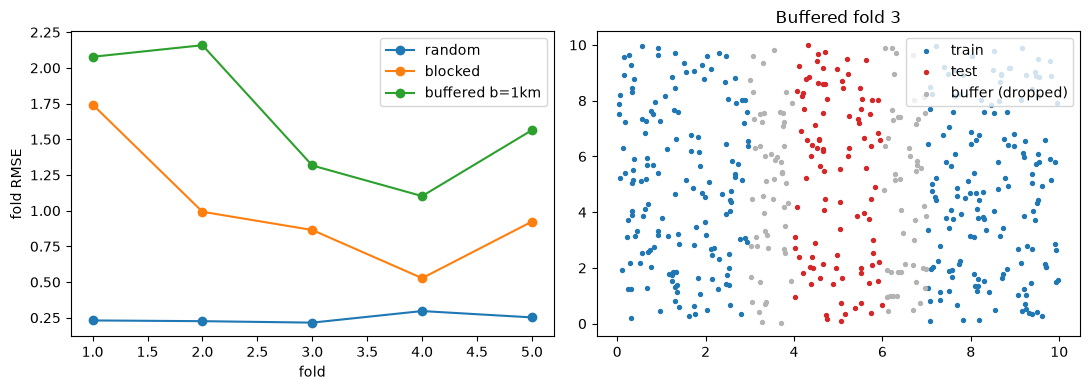

fold RMSEs blocked: [1.743 0.992 0.865 0.527 0.924]


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, (r, med, pf) in results.items():
    axes[0].plot(range(1, 6), pf, "o-", label=name)
axes[0].set_xlabel("fold"); axes[0].set_ylabel("fold RMSE"); axes[0].legend()

tr, te = strip_folds(1.0)[2]
axes[1].scatter(*coords[tr].T, s=8, c="C0", label="train")
axes[1].scatter(*coords[te].T, s=8, c="C3", label="test")
dropped = np.setdiff1d(np.arange(n), np.concatenate([tr, te]))
axes[1].scatter(*coords[dropped].T, s=8, c="0.7", label="buffer (dropped)")
axes[1].legend(); axes[1].set_title("Buffered fold 3")
plt.tight_layout(); plt.show()
print("fold RMSEs blocked:", np.round(results["blocked"][2], 3))

## Leakage demonstration

A neighborhood-mean feature built from outcomes *before* splitting contains test outcomes. We compare a predictor using that feature (computed on all data, leaky) with one where each test point's feature uses only training outcomes (clean).

In [5]:
def nbr_mean_all(i_set, k=5):
    # leaky: neighbors drawn from ALL points other than itself (may include test points)
    d = cdist(coords[i_set], coords); d[np.arange(len(i_set)), i_set] = np.inf
    return y[np.argsort(d, 1)[:, :k]].mean(1)

def nbr_mean_train(i_set, tr, k=5):
    d = cdist(coords[i_set], coords[tr])
    for r, i in enumerate(i_set):
        d[r, tr == i] = np.inf
    return y[tr][np.argsort(d, 1)[:, :k]].mean(1)

leaky, clean = [], []
for tr, te in strip_folds(0.0):
    # test feature leaky: uses test neighbors' outcomes; clean: training only
    leaky.append((y[te] - nbr_mean_all(te)) ** 2)
    clean.append((y[te] - nbr_mean_train(te, tr)) ** 2)
print("RMSE using all-data neighborhood feature:", np.sqrt(np.concatenate(leaky).mean()).round(3))
print("RMSE using training-only feature        :", np.sqrt(np.concatenate(clean).mean()).round(3))

RMSE using all-data neighborhood feature: 0.252
RMSE using training-only feature        : 1.078


The leaky number is optimistic because test points borrow from each other's outcomes; only the training-only version resembles deployment.